In [1]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from scipy.signal import convolve2d

## 1

on paper : Convexity and computation of the grad with the TH 7.3

Ask to Mh or Lukas

## 2

On paper: 

# Denoising with variational approaches

In [2]:
def scalar_product(u, v):
    if u.ndim > 2:
        return np.sum(u * v, axis=0)
    else:
        return np.sum(u * v)

def norm(u):
    return np.sqrt(scalar_product(u, u))

In [3]:
def gradient(u):
    m, n = u.shape
    grad_u = np.zeros((2, m, n))
    
    grad_u[0, :-1, :] = u[1:] - u[:-1]
    
    grad_u[1, :, :-1] = u[:, 1:] - u[:, :-1]
    
    return grad_u

In [4]:
def div(p):
    m, n = p.shape[1:]
    
    div_1 = np.zeros((m, n))
    div_1[:-1, :] = p[0, :-1, :]
    div_1[1:, :] -= p[0, :-1, :]
    
    div_2 = np.zeros((m, n))
    div_2[:, :-1] = p[1, :, :-1]
    div_2[:, 1:] -= p[1, :, :-1]
    
    return div_1 + div_2

In [5]:
def laplacian(u):
    return div(gradient(u))

#### Image setup

In [6]:
def load_img(fname, dirname='images/'):
    Im_PIL = Image.open(dirname + fname)
    return np.array(Im_PIL)

In [7]:
def add_gaussian_noise(I, s):
    m, n = I.shape
    
    I_out = I + s * np.random.randn(m, n)
    
    return I_out

In [8]:
# Load image
Im_data = load_img('cameraman.png', dirname='images/')

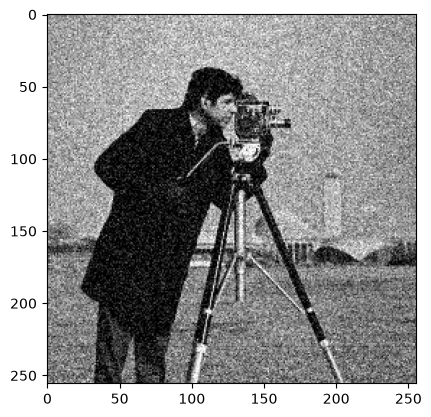

In [9]:
# Noise image
Im_noised = add_gaussian_noise(Im_data, s=30)

bounds = {'vmin': 0, 'vmax': 255}
plt.imshow(Im_noised, cmap='gray', **bounds)

plt.show()

#### Convergence criteria

In [10]:
def convergence_criteria(u0, u1, conv_crit):
    """
    Vérifie si la norme relative de la différence entre deux itérations
    est inférieure au seuil conv_crit.
    """
    err = norm(u1 - u0) / (norm(u0) + 1e-12)
    return err < conv_crit

## 3

In [11]:
def Denoise_Tikhonov(f, K, lamb, tau=None, conv_crit=1e-5):
    
    if tau is None:
        tau = 1.0 / (lamb + 4.0)
        
    u = f.astype(np.float64).copy()
    
    for k in range(K):
        u_prev = u.copy()
        
        # u^{k+1} = u^k + tau * (lamb * (f - u^k) + Delta u^k)
        u = u + tau * (lamb * (f - u) + laplacian(u))
        
        if convergence_criteria(u_prev, u, conv_crit):
            # print(f"Tikhonov convergé en {k+1} itérations.")
            break
            
    return u

## 5.1
### Test of `Denoise_Tikhonov` 

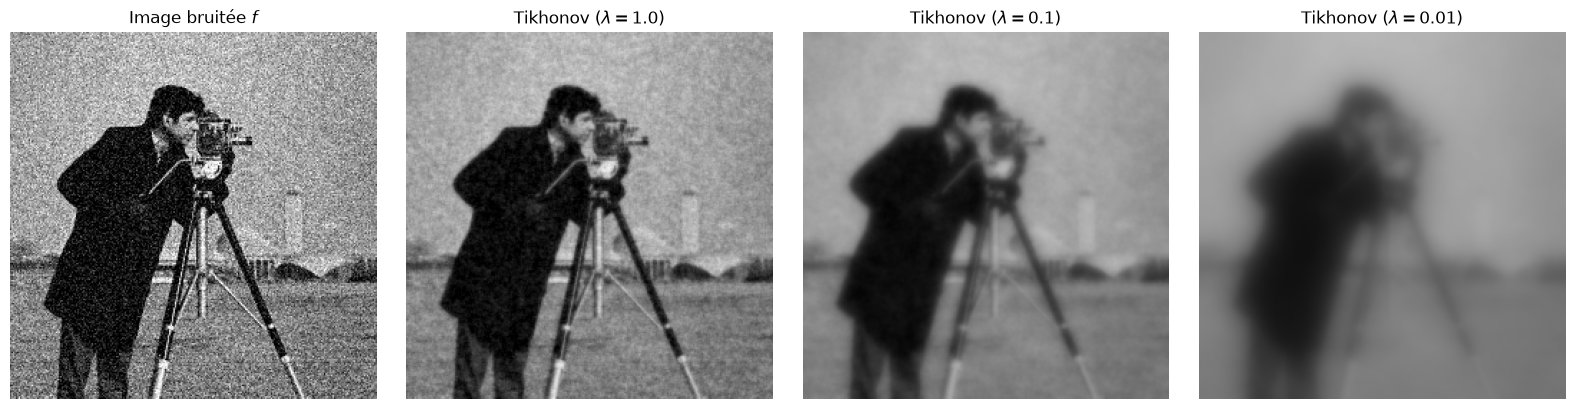

In [12]:
lambdas_tik = [1.0, 0.1, 0.01]
K_max = 1000

fig, axes = plt.subplots(1, len(lambdas_tik) + 1, figsize=(16, 4))
axes[0].imshow(Im_noised, cmap='gray', **bounds)
axes[0].set_title("Image bruitée $f$")
axes[0].axis('off')

for i, lamb in enumerate(lambdas_tik):
    u_tik = Denoise_Tikhonov(Im_noised, K=K_max, lamb=lamb)
    axes[i+1].imshow(u_tik, cmap='gray', **bounds)
    axes[i+1].set_title(f"Tikhonov ($\lambda = {lamb}$)")
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

More the Lambda argu increas more the image be denoised but we lose the quality...

## 4

In [13]:
def Denoise_TV(f, K, lamb, eps=1.0, tau=0.1, conv_crit=1e-4):

    u = f.astype(np.float64).copy()
    
    for k in range(K):
        u_prev = u.copy()
        
        # Calcul du gradient spatial
        grad = gradient(u)  # shape (2, m, n)
        
        # ||grad(u)||^2 = (grad_x)^2 + (grad_y)^2
        norm_grad = np.sqrt(np.sum(grad**2, axis=0) + eps)
        
        # grad(u) / sqrt(||grad(u)||^2 + eps)
        flux = grad / norm_grad
        
        # Descente de gradient
        u = u + tau * (lamb * (f - u) + div(flux))
        
        if convergence_criteria(u_prev, u, conv_crit):
            # print(f"TV convergé en {k+1} itérations.")
            break
            
    return u

## 5.2
### Test of `Denoise_TV`

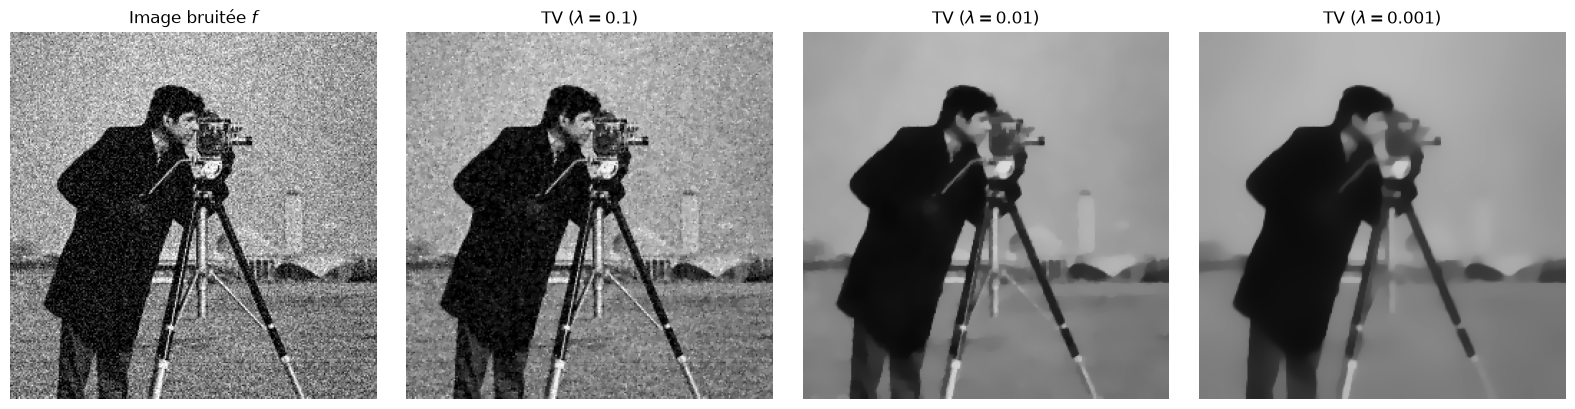

In [14]:
lambdas_tv = [0.1, 0.01, 0.001]
K_max = 1000
eps = 1.0
tau_tv = 0.1  # Doit rester modéré pour garantir la stabilité numérique

fig, axes = plt.subplots(1, len(lambdas_tv) + 1, figsize=(16, 4))
axes[0].imshow(Im_noised, cmap='gray', **bounds)
axes[0].set_title("Image bruitée $f$")
axes[0].axis('off')

for i, lamb in enumerate(lambdas_tv):
    u_tv = Denoise_TV(Im_noised, K=K_max, lamb=lamb, eps=eps, tau=tau_tv)
    axes[i+1].imshow(u_tv, cmap='gray', **bounds)
    axes[i+1].set_title(f"TV ($\lambda = {lamb}$)")
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

With a better lambda argu, the image is more denoised and we lose less quality than the previous method (1.6) 

## 6

In [15]:
def Denoise_Tikhonov_DFT(f, lamb):
    m, n = f.shape

    # 1. Grille des fréquences (p, q)
    p = np.arange(m)[:, None]  # shape (m, 1)
    q = np.arange(n)[None, :]  # shape (1, n)

    # 2. Valeurs propres / symbole de Fourier du laplacien discret
    # L_hat = 2*(cos(2*pi*p/m) - 1) + 2*(cos(2*pi*q/n) - 1)
    L_hat = -4.0 * (
        np.sin(np.pi * p / m) ** 2 + np.sin(np.pi * q / n) ** 2
    )  #

    # 3. FFT de l'image bruitée f
    f_hat = np.fft.fft2(f)

    # 4. Inversion dans le domaine fréquentiel
    u_hat = (lamb * f_hat) / (lamb - L_hat)

    # 5. Transformée inverse (partie réelle)
    u = np.real(np.fft.ifft2(u_hat))

    return u

### Test of `Denoise_Tikhonov_Fourier` 

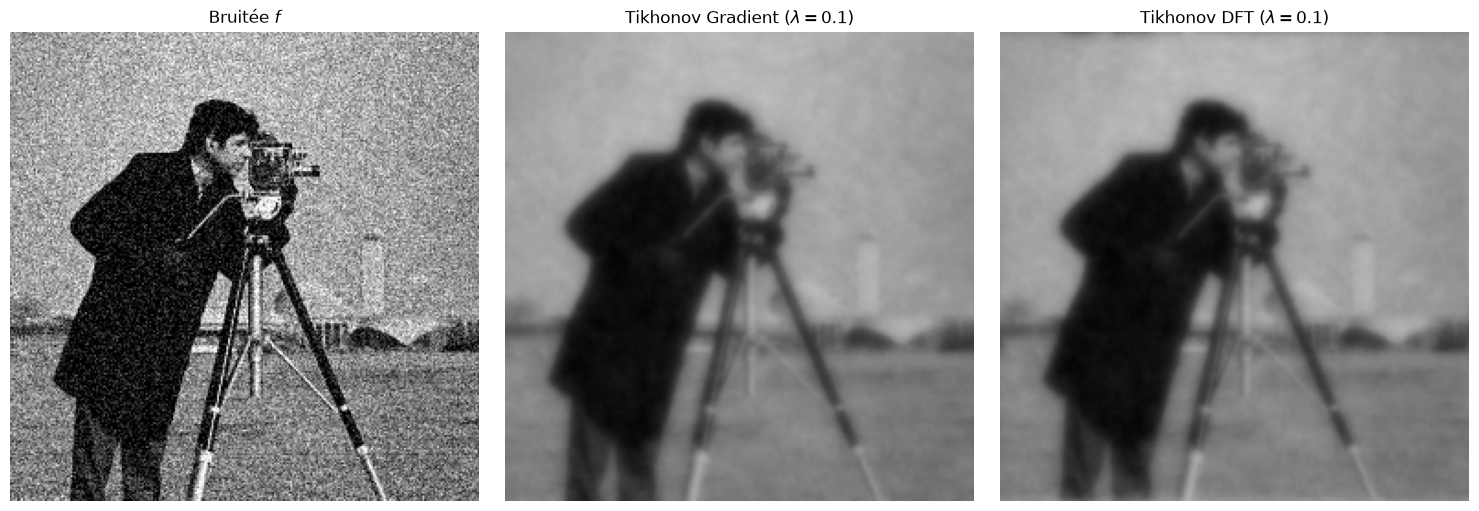

In [16]:
lamb = 0.1
u_tik_grad = Denoise_Tikhonov(Im_noised, K=1500, lamb=lamb)
u_tik_dft = Denoise_Tikhonov_DFT(Im_noised, lamb=lamb)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(Im_noised, cmap='gray', **bounds)
axes[0].set_title('Bruitée $f$')
axes[0].axis('off')

axes[1].imshow(u_tik_grad, cmap='gray', **bounds)
axes[1].set_title(f'Tikhonov Gradient ($\lambda = {lamb}$)')
axes[1].axis('off')

axes[2].imshow(u_tik_dft, cmap='gray', **bounds)
axes[2].set_title(f'Tikhonov DFT ($\lambda = {lamb}$)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

tne two images are to blury..

## 7

On paper

# Extensions to deconvolution and inpainting

## 8

On paper

#### Load images

In [17]:
# Image : Parrot
Im_parrot = load_img('Im1.png')
Mask_parrot = load_img('Im1_mask.png')

# Image : Beach
Im_beach = load_img('Im2.png')
Mask_beach = load_img('Im2_mask.png')

# Image : Mystery text
Im_mystery = load_img('Im3.png')
Mask_mystery = load_img('Im3_mask.png')

In [18]:
def gaussian_kernel(size, sigma):
    variance = sigma**2
    half_size = size // 2
    
    range_matrix = np.arange(- half_size, half_size + 1)
    X, Y = np.meshgrid(range_matrix, range_matrix)
    
    return np.exp(- (X**2 + Y**2) / (2 * variance)) / (2 * np.pi * variance)

In [19]:
def convolve(f, G):
    return convolve2d(f, G, mode='same', boundary='symm')

## 9

In [20]:
def Deconvolution_TV(f, G, tau, eps, K, lamb):
    u = f.astype(np.float64).copy()
    
    for k in range(K):
        # Terme d'attache aux données : G * (f - G * u)
        Gu = convolve2d(u, G, mode='same', boundary='symm')
        data_term = convolve2d(f - Gu, G, mode='same', boundary='symm')
        
        # Terme de régularisation TV : div( grad(u) / sqrt(||grad(u)||^2 + eps^2) )
        grad_u = gradient(u)
        norm_grad = np.sqrt(grad_u[0]**2 + grad_u[1]**2 + eps**2)
        flux = grad_u / norm_grad
        reg_term = div(flux)
        
        # Schéma de descente de gradient (équation 2.18)
        u = u + tau * (lamb * data_term + reg_term)
        
    return u

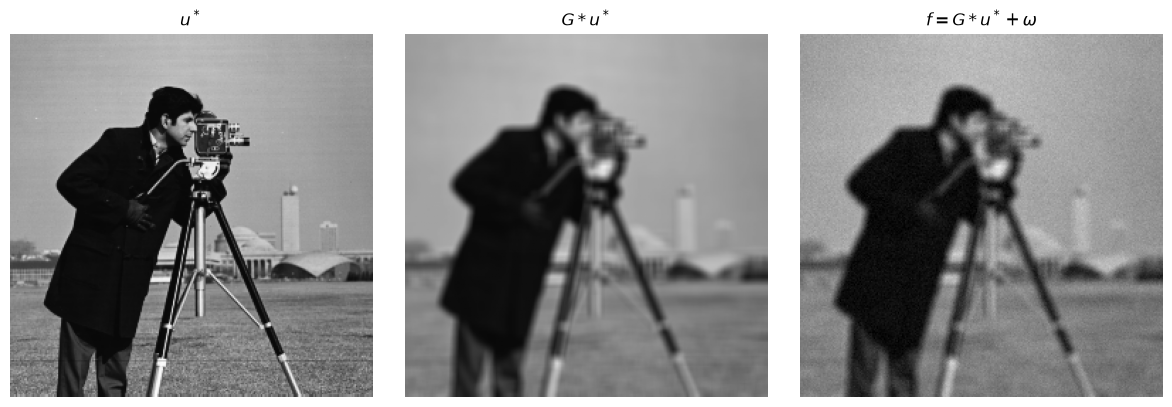

In [21]:
np.random.seed(0)

# Noyau gaussien normalisé (somme = 1) pour ne pas assombrir l'image
G = gaussian_kernel(size=7, sigma=5)
G = G / G.sum()

Im_convolved = convolve(Im_data.astype(np.float64), G)        # G * u*
Im_convolved_noised = add_gaussian_noise(Im_convolved, s=5)   # f = G * u* + w

def rmse(u, ref):
    return np.sqrt(np.mean((u - ref) ** 2))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, title in zip(axes,
                         [Im_data, Im_convolved, Im_convolved_noised],
                         ["$u^*$", "$G * u^*$", "$f = G * u^* + \\omega$"]):
    ax.imshow(im, cmap='gray', **bounds)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 12.1
### Test of `Deconvolution_TV`

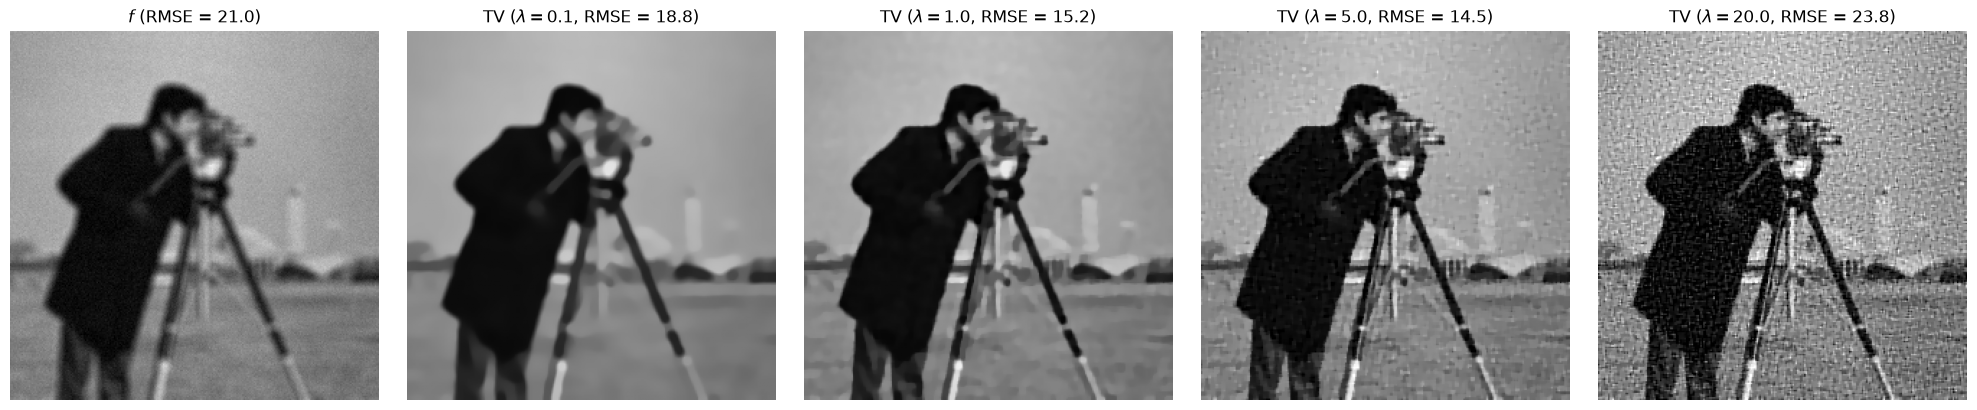

In [22]:
lambdas_deconv = [0.1, 1.0, 5.0, 20.0]
K_deconv = 500
eps = 1.0

fig, axes = plt.subplots(1, len(lambdas_deconv) + 1, figsize=(20, 4))
axes[0].imshow(Im_convolved_noised, cmap='gray', **bounds)
axes[0].set_title(f"$f$ (RMSE = {rmse(Im_convolved_noised, Im_data):.1f})")
axes[0].axis('off')

for i, lamb in enumerate(lambdas_deconv):
    tau = 1.0 / (lamb + 8.0 / eps)   # pas stable : tau < 2 / L
    u_deconv = Deconvolution_TV(Im_convolved_noised, G, tau=tau, eps=eps, K=K_deconv, lamb=lamb)
    axes[i+1].imshow(u_deconv, cmap='gray', **bounds)
    axes[i+1].set_title(f"TV ($\\lambda = {lamb}$, RMSE = {rmse(u_deconv, Im_data):.1f})")
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

## 10

In [23]:
def Inpainting_TV(f, M, tau, eps, K, lamb):
    u = f.astype(np.float64).copy()
    
    for k in range(K):
        # Terme d'attache aux données : M * (f - u)
        data_term = M * (f - u)
        
        # Terme de régularisation TV : div( grad(u) / sqrt(||grad(u)||^2 + eps^2) )
        grad_u = gradient(u)
        norm_grad = np.sqrt(grad_u[0]**2 + grad_u[1]**2 + eps**2)
        flux = grad_u / norm_grad
        reg_term = div(flux)
        
        # Schéma de descente de gradient (équation 2.20)
        u = u + tau * (lamb * data_term + reg_term)

    return u

## 12.2
### Test of `Inpainting_TV`

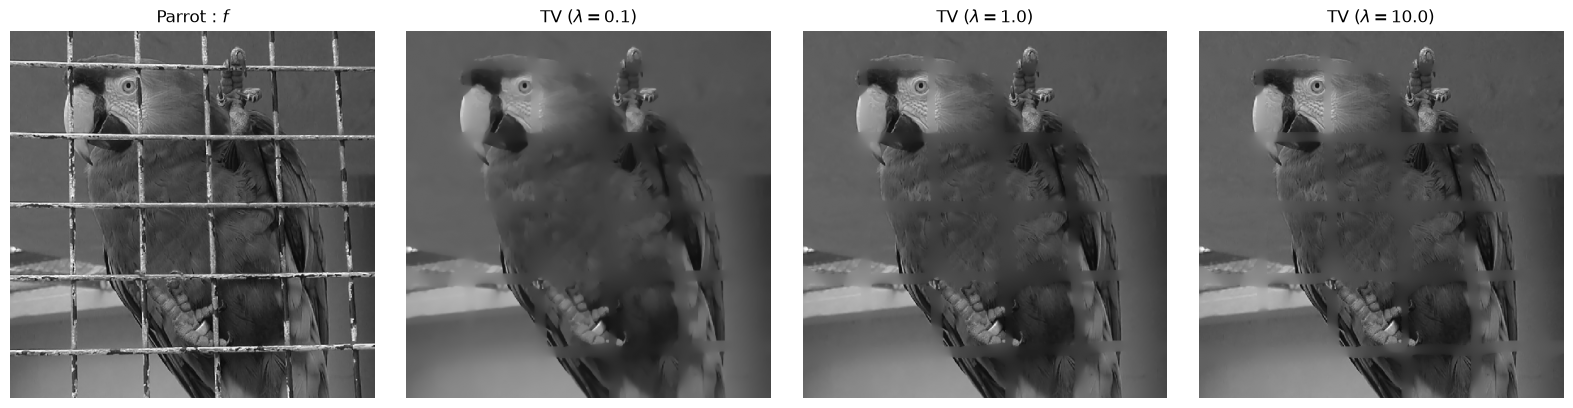

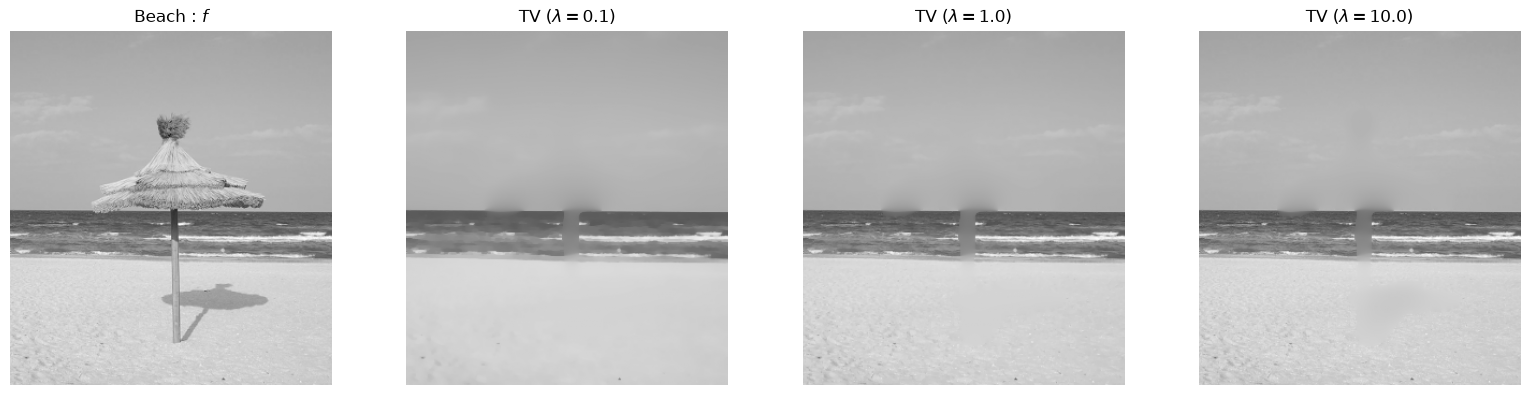

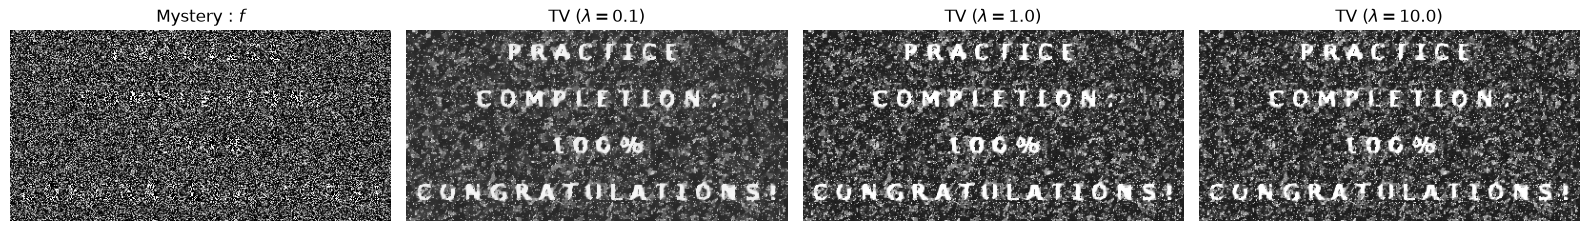

In [24]:
lambdas_inp_tv = [0.1, 1.0, 10.0]
K_inp_tv = 8000   # grand K : la diffusion TV est lente pour combler les trous (~1 min au total)
eps = 1.0

for name, Im, Mask in [("Parrot", Im_parrot, Mask_parrot),
                       ("Beach", Im_beach, Mask_beach),
                       ("Mystery", Im_mystery, Mask_mystery)]:
    M = (Mask > 0).astype(np.float64)   # masque 0/255 -> 0/1

    fig, axes = plt.subplots(1, len(lambdas_inp_tv) + 1, figsize=(16, 4))
    axes[0].imshow(Im, cmap='gray', **bounds)
    axes[0].set_title(f"{name} : $f$")
    axes[0].axis('off')

    for i, lamb in enumerate(lambdas_inp_tv):
        u_inp = Inpainting_TV(Im, M, tau=1.0 / (lamb + 8.0 / eps), eps=eps, K=K_inp_tv, lamb=lamb)
        axes[i+1].imshow(u_inp, cmap='gray', **bounds)
        axes[i+1].set_title(f"TV ($\\lambda = {lamb}$)")
        axes[i+1].axis('off')

    plt.tight_layout()
    plt.show()

## 11

In [25]:
def Inpainting_Tikhonov(f, M, tau, K, lamb, conv_crit=1e-6):
    """
    Inpainting avec régularisation de Tikhonov (équation 2.20) :
        u^{k+1} = u^k + tau * ( lamb * (f - u^k) * M + Delta u^k )
    f : image partiellement observée
    M : masque (1 = pixel connu, 0 = pixel à reconstruire), accepte aussi 0/255
    tau : pas de temps (stable si tau < 2 / (lamb + 8), ex. 1 / (lamb + 4))
    """
    f = f.astype(np.float64)
    M = (M > 0).astype(np.float64)   # normalise le masque en {0, 1}

    u = f.copy()

    for k in range(K):
        u_prev = u.copy()

        # Attache aux données uniquement sur les pixels connus + diffusion isotrope
        u = u + tau * (lamb * (f - u) * M + laplacian(u))

        if convergence_criteria(u_prev, u, conv_crit):
            # print(f"Inpainting Tikhonov convergé en {k+1} itérations.")
            break

    return u

## 12.3
### Test of `Inpainting_Tikhonov`

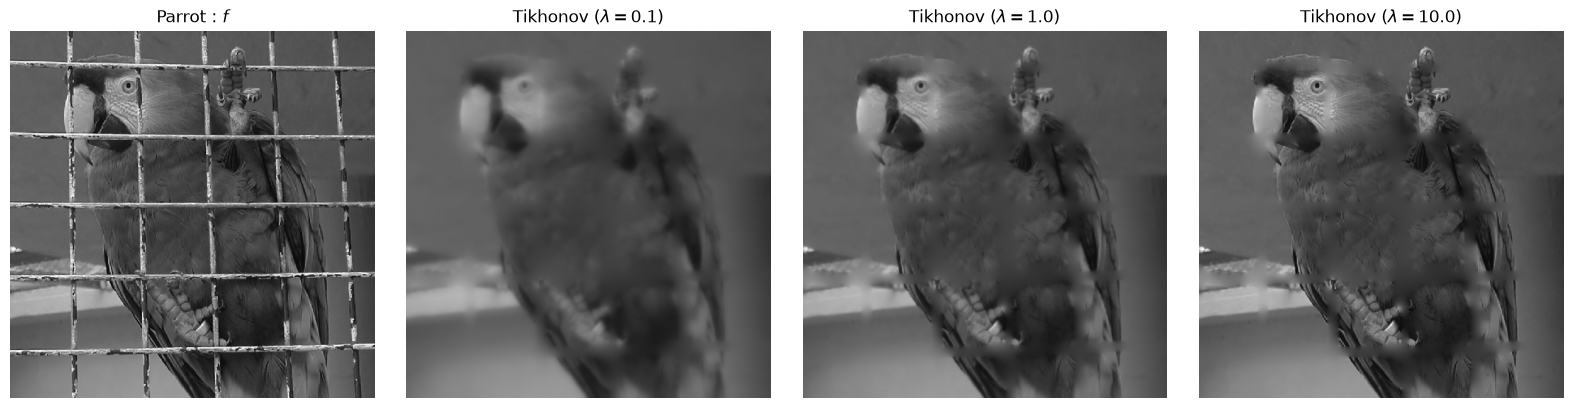

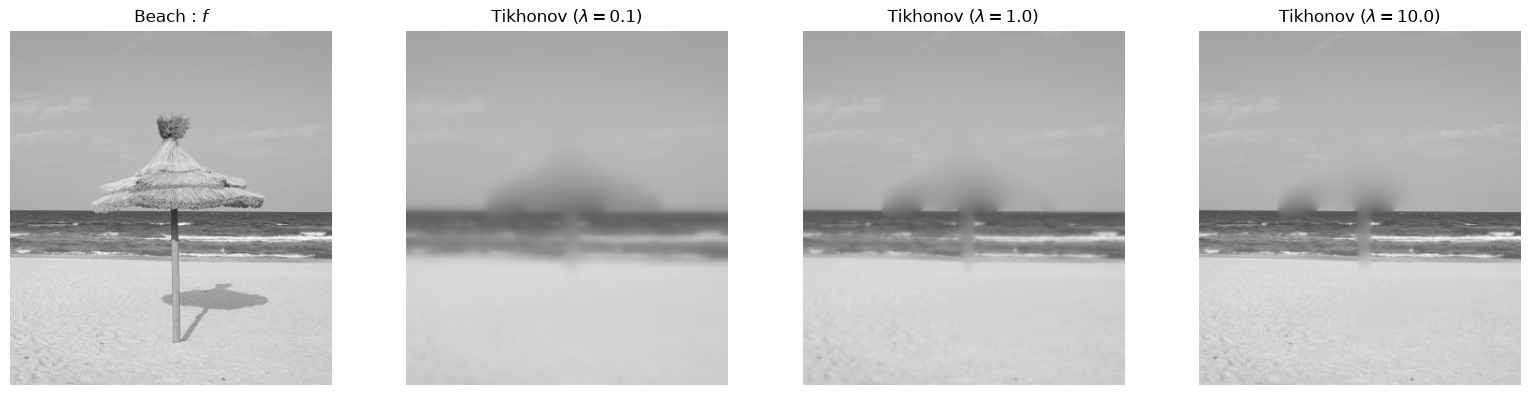

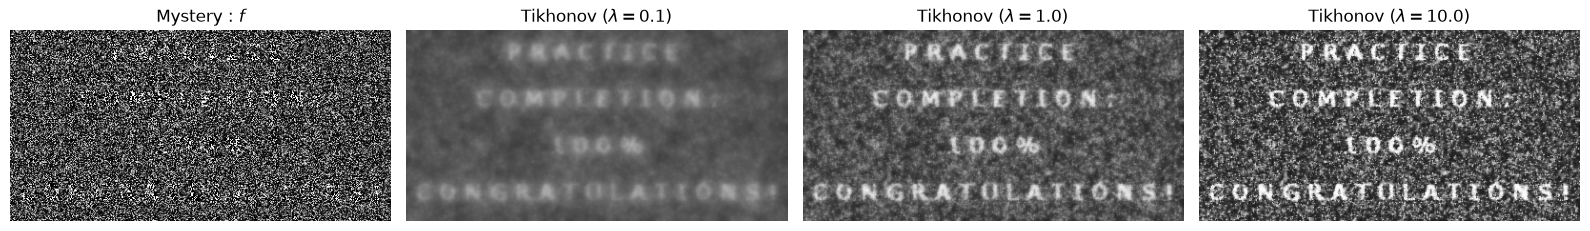

In [26]:
lambdas_inp = [0.1, 1.0, 10.0]
K_inp = 5000

for name, Im, Mask in [("Parrot", Im_parrot, Mask_parrot),
                       ("Beach", Im_beach, Mask_beach),
                       ("Mystery", Im_mystery, Mask_mystery)]:
    fig, axes = plt.subplots(1, len(lambdas_inp) + 1, figsize=(16, 4))
    axes[0].imshow(Im, cmap='gray', **bounds)
    axes[0].set_title(f"{name} : $f$")
    axes[0].axis('off')

    for i, lamb in enumerate(lambdas_inp):
        u_inp = Inpainting_Tikhonov(Im, Mask, tau=1.0 / (lamb + 4.0), K=K_inp, lamb=lamb)
        axes[i+1].imshow(u_inp, cmap='gray', **bounds)
        axes[i+1].set_title(f"Tikhonov ($\\lambda = {lamb}$)")
        axes[i+1].axis('off')

    plt.tight_layout()
    plt.show()

## 13

On paper

## 14

### Conditions d'optimalité

On minimise $J_\lambda(u) = \frac{\lambda}{2}\|u - f\|^2 + \sum_{x} \phi(\|\nabla u(x)\|)$.

Pour un $\phi$ dérivable, le gradient du terme de régularisation est
$\nabla J_R(u) = -\operatorname{div}\left( \frac{\phi'(\|\nabla u\|)}{\|\nabla u\|} \nabla u \right)$,
donc la condition d'optimalité (Euler-Lagrange) s'écrit :

$$\lambda (u - f) - \operatorname{div}\left( \frac{\phi'(\|\nabla u\|)}{\|\nabla u\|} \nabla u \right) = 0$$

| | $\phi(\xi)$ | $\phi'(\xi)$ | $\phi'(\xi)/\xi$ | Condition d'optimalité |
|---|---|---|---|---|
| TV lissée | $\sqrt{\xi^2 + 1}$ | $\frac{\xi}{\sqrt{\xi^2+1}}$ | $\frac{1}{\sqrt{\xi^2+1}}$ | $\lambda(u-f) - \operatorname{div}\left(\frac{\nabla u}{\sqrt{\|\nabla u\|^2+1}}\right) = 0$ |
| $\phi_1$ | $\frac{\xi^2}{1+\xi^2}$ | $\frac{2\xi}{(1+\xi^2)^2}$ | $\frac{2}{(1+\xi^2)^2}$ | $\lambda(u-f) - \operatorname{div}\left(\frac{2\nabla u}{(1+\|\nabla u\|^2)^2}\right) = 0$ |
| $\phi_2$ | $\log(1+\xi^2)$ | $\frac{2\xi}{1+\xi^2}$ | $\frac{2}{1+\xi^2}$ | $\lambda(u-f) - \operatorname{div}\left(\frac{2\nabla u}{1+\|\nabla u\|^2}\right) = 0$ |

Remarque : $\phi_1$ et $\phi_2$ ne sont **pas convexes** (concaves pour $\xi$ grand), donc cette condition est seulement nécessaire : la descente de gradient converge vers un point critique qui dépend de l'initialisation $u^0 = f$.

En pratique, les pixels valent entre 0 et 255, donc on remplace $\xi$ par $\xi/\varepsilon$ (fonction $\varepsilon^2\phi(\xi/\varepsilon)$) : $\varepsilon$ fixe le seuil de contraste à partir duquel un gradient est considéré comme un contour.

In [ ]:
def Denoise_g1(f, K, lamb, eps, tau, conv_crit=1e-5):
    """
    Débruitage avec phi_1(xi) = xi^2 / (1 + xi^2)   (non convexe)
    On utilise la version mise à l'échelle  eps^2 * phi_1(|grad u| / eps) :
    eps joue le rôle de seuil de contraste (gradients >> eps = contours conservés).

    Descente de gradient :
        u^{k+1} = u^k + tau * ( lamb * (f - u^k) + div( w1(|grad u^k|) * grad u^k ) )
    avec  w1(t) = phi_1'(s) / s = 2 / (1 + s^2)^2,   s = t / eps.
    Stable pour tau < 2 / (lamb + 16)  (w1 <= 2 et constante du laplacien = 8).
    """
    f = f.astype(np.float64)
    u = f.copy()

    for k in range(K):
        u_prev = u.copy()

        grad = gradient(u)                         # shape (2, m, n)
        s2 = np.sum(grad**2, axis=0) / eps**2      # (|grad u| / eps)^2
        w = 2.0 / (1.0 + s2)**2                    # phi_1'(s) / s

        u = u + tau * (lamb * (f - u) + div(w * grad))

        if convergence_criteria(u_prev, u, conv_crit):
            break

    return u

In [ ]:
def Denoise_g2(f, K, lamb, eps, tau, conv_crit=1e-5):
    """
    Débruitage avec phi_2(xi) = log(1 + xi^2)   (non convexe)
    Version mise à l'échelle  eps^2 * phi_2(|grad u| / eps).

    Descente de gradient :
        u^{k+1} = u^k + tau * ( lamb * (f - u^k) + div( w2(|grad u^k|) * grad u^k ) )
    avec  w2(t) = phi_2'(s) / s = 2 / (1 + s^2),   s = t / eps.
    (c'est exactement le coefficient de diffusion de Perona-Malik)
    Stable pour tau < 2 / (lamb + 16).
    """
    f = f.astype(np.float64)
    u = f.copy()

    for k in range(K):
        u_prev = u.copy()

        grad = gradient(u)
        s2 = np.sum(grad**2, axis=0) / eps**2
        w = 2.0 / (1.0 + s2)                       # phi_2'(s) / s

        u = u + tau * (lamb * (f - u) + div(w * grad))

        if convergence_criteria(u_prev, u, conv_crit):
            break

    return u

#### Comparison `Denoise_TV`, `Denoise_g1`, `Denoise_g2`

In [ ]:
lamb_cmp = 0.01
K_cmp = 300
tau_cmp = 0.1          # < 2 / (lamb + 16) : stable pour les trois méthodes
eps_g1 = 20.0          # seuil de contraste pour phi_1
eps_g2 = 5.0           # seuil de contraste pour phi_2

u_tv = Denoise_TV(Im_noised, K=1000, lamb=lamb_cmp, eps=1.0, tau=tau_cmp)
u_g1 = Denoise_g1(Im_noised, K=K_cmp, lamb=lamb_cmp, eps=eps_g1, tau=tau_cmp)
u_g2 = Denoise_g2(Im_noised, K=K_cmp, lamb=lamb_cmp, eps=eps_g2, tau=tau_cmp)

def rmse(u, ref):
    return np.sqrt(np.mean((u - ref) ** 2))

images = [Im_noised, u_tv, u_g1, u_g2]
titles = ["$f$ bruitée", "TV", f"$\\phi_1$ ($\\varepsilon$={eps_g1})", f"$\\phi_2$ ($\\varepsilon$={eps_g2})"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, im, t in zip(axes, images, titles):
    ax.imshow(im, cmap='gray', **bounds)
    ax.set_title(f"{t}\nRMSE = {rmse(im, Im_data):.1f}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# Influence de eps (seuil de contraste)
eps_list = [5.0, 10.0, 20.0, 40.0]
fig, axes = plt.subplots(2, len(eps_list), figsize=(20, 9))
for j, e in enumerate(eps_list):
    for i, (name, fn) in enumerate([("$\\phi_1$", Denoise_g1), ("$\\phi_2$", Denoise_g2)]):
        u = fn(Im_noised, K=K_cmp, lamb=lamb_cmp, eps=e, tau=tau_cmp)
        axes[i, j].imshow(u, cmap='gray', **bounds)
        axes[i, j].set_title(f"{name}, $\\varepsilon$={e}, RMSE = {rmse(u, Im_data):.1f}")
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

### Commentaires

- **Qualité** (bruit $\sigma=30$, RMSE de $f$ ≈ 29.9, $\lambda=0.01$) : $\phi_2$ avec $\varepsilon=5$ donne la meilleure erreur (RMSE ≈ 12.3) ; $\phi_1$ avec $\varepsilon=20$ (≈ 14.5) est au niveau de la TV lissée (≈ 14.2). Mais avec un mauvais $\varepsilon$, $\phi_1$ et $\phi_2$ peuvent être bien pires que la TV (voir la deuxième figure).
- **Préservation des contours** : le poids $\phi'(\xi)/\xi$ décroît en $1/\xi$ pour TV, en $1/\xi^2$ pour $\phi_2$ et en $1/\xi^4$ pour $\phi_1$. Plus il décroît vite, moins on diffuse à travers les forts gradients : les contours restent nets, les zones plates sont lissées.
- **Rôle de $\varepsilon$** : c'est un seuil de contraste. Trop petit, le bruit est vu comme des contours et n'est pas retiré ; trop grand, les vrais contours sont lissés. Le bon $\varepsilon$ n'est pas le même pour $\phi_1$ et $\phi_2$, et il dépend du niveau de bruit.
- **Non-convexité** : contrairement à Tikhonov et à la TV, $J_\lambda$ n'est plus convexe. Il n'y a pas d'unicité du minimiseur, le résultat dépend de l'initialisation ($u^0 = f$) et du nombre d'itérations. $\phi_1$ est bornée (elle « sature » à 1) : elle pénalise à peu près pareil tous les grands sauts, ce qui favorise des images constantes par morceaux.
- **Rôle de $\lambda$** : comme avant, il équilibre attache aux données et régularisation ; ici $\lambda$ influe moins que $\varepsilon$ sur le résultat.